# Level 1: The normal Zeeman effect

**Goal.** See, in numbers and plots, that a magnetic field splits an orbital level into equally
spaced components, and that this produces the famous Lorentz *triplet*.

**Physics.** An electron with orbital angular momentum $\mathbf L$ has a magnetic moment
$-\mu_B\mathbf L/\hbar$. In a field $B$ along $z$ the energy shifts by

$$\Delta E = \mu_B B\, m_l, \qquad m_l = -l,\dots,+l .$$

**Trick used here.** The real electron also has spin. To isolate the *orbital-only* effect we switch
spin off in the code: spin-orbit constant $\zeta = 0$ and spin g-factor $g_s = 0$.

level spacing per tesla (eV/T): 5.788381798199999e-05
Bohr magneton mu_B       (eV/T): 5.7883817982e-05


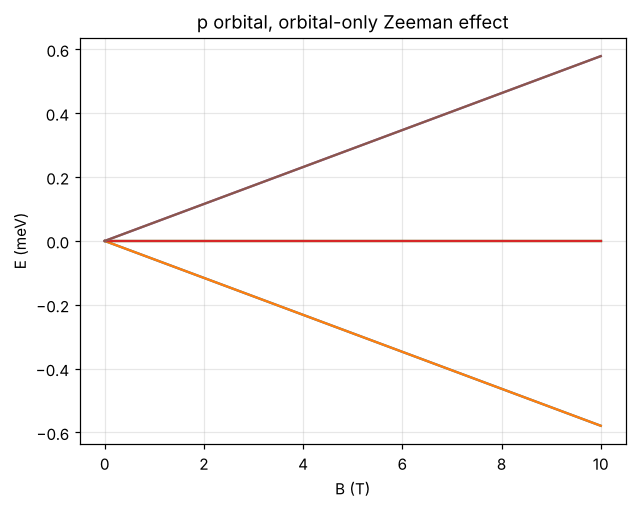

In [1]:
import sys
sys.path.insert(0, '..')          # so `import src...` works from the notebooks folder
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
from src.solvers import energy_vs_field
from src.constants import MU_B_EV

b = np.linspace(0, 10, 50)                        # tesla
e = energy_vs_field(1, b, 0.0, g_s=0.0)           # l=1, zeta=0, g_s=0 -> orbital only
plt.plot(b, e * 1e3)
plt.xlabel('B (T)'); plt.ylabel('E (meV)'); plt.title('p orbital, orbital-only Zeeman effect')
plt.show()

spacing_per_tesla = (e[-1, -1] - e[-1, 0]) / 2 / b[-1]
print('level spacing per tesla (eV/T):', spacing_per_tesla)
print('Bohr magneton mu_B       (eV/T):', MU_B_EV)

Three distinct lines appear (each is doubly degenerate because spin is switched off): $m_l=-1,0,+1$.
The measured spacing per tesla equals the Bohr magneton, as the formula predicts.

## The Lorentz triplet

Now let the p level decay to an s level. Selection rules (Level 4 explains why) allow
$\Delta m_l = 0, \pm 1$, so we see three lines: an unshifted $\pi$ line and two $\sigma$ lines
shifted by $\pm\mu_B B$.

polarisation  wavenumber_cm1  intensity
      sigma-         -0.4669        1.0
      sigma-         -0.4669        1.0
          pi          0.0000        1.0
          pi          0.0000        1.0
      sigma+          0.4669        1.0
      sigma+          0.4669        1.0
mu_B B / (h c) at 1 T = 0.4669 cm^-1


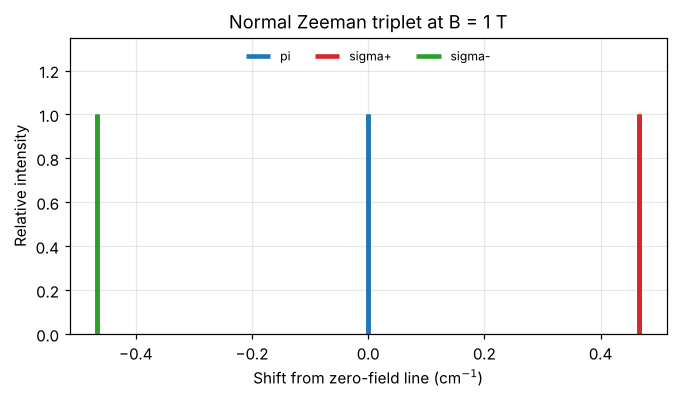

In [2]:
from src.transitions import zeeman_lines
from src.animation import plot_stick_spectrum
from src.constants import MU_B_J, HBAR
import scipy.constants as sc

df = zeeman_lines(1, 0, 1.0, 0.0, 0.0, 0.0, g_s=0.0)   # B = 1 T, p -> s
print(df[['polarisation', 'wavenumber_cm1', 'intensity']].round(4).to_string(index=False))
print('mu_B B / (h c) at 1 T = %.4f cm^-1' % (MU_B_J * 1.0 / (sc.h * sc.c) / 100))

plot_stick_spectrum(df, 0.0, title='Normal Zeeman triplet at B = 1 T')
plt.show()

The table lists 6 components, but they sit at only **3 distinct positions**: spin-up and spin-down give
identical shifts when spin is switched off, so they lie on top of each other. The shifts are
$-0.467,\ 0,\ +0.467\ \mathrm{cm^{-1}}$ per tesla, exactly $\mu_B B/(hc)$.

## Does it depend on $l$?

For a level with orbital momentum $l$ there are $2l+1$ equally spaced sublevels. Check $l=2$:

In [3]:
for l in (1, 2, 3):
    levels = np.unique(np.round(energy_vs_field(l, [1.0], 0.0, g_s=0.0)[0] / MU_B_EV, 6))
    print('l =', l, ' energies / (mu_B B) =', levels)

l = 1  energies / (mu_B B) = [-1.  0.  1.]
l = 2  energies / (mu_B B) = [-2. -1.  0.  1.  2.]
l = 3  energies / (mu_B B) = [-3. -2. -1.  0.  1.  2.  3.]


**Take-away.** With spin ignored, the Hamiltonian is just $\mu_B B L_z$. Its eigenvalues are the integers
$m_l$ in units of $\mu_B B$, and the spectrum is a symmetric triplet. Real atoms usually show *more*
than three lines. That is the anomalous Zeeman effect (Level 2).